In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sklearn

**Для начача посмотрим на датасет.**

In [2]:
df = pd.read_csv("used_cars.csv")
print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")
df.head()

Количество строк: 4009
Количество столбцов: 12


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


***Посмотрим на столбцы.***

In [3]:
overview = pd.DataFrame({
    "тип": df.dtypes,
    "пропуски": df.isna().sum(),
    "уникальные значения": df.nunique(),
})
overview

,тип,пропуски,уникальные значения
brand,str,0,57
model,str,0,1898
model_year,int64,0,34
milage,str,0,2818
fuel_type,str,170,7
engine,str,0,1146
transmission,str,0,62
ext_col,str,0,319
int_col,str,0,156
accident,str,113,2


**Заполним пропуски/неизвестность "unknown".**

In [4]:
df_filled = df.copy()

cols_to_fill = ["fuel_type", "accident", "clean_title"]
df_filled[cols_to_fill] = df_filled[cols_to_fill].fillna("unknown")
df_filled["fuel_type"] = df_filled["fuel_type"].replace(["–", "not supported"], "unknown")

df_filled["milage"] = pd.to_numeric(
    df_filled["milage"].str.replace(r",| mi\.", "", regex=True)
)
df_filled["price"] = pd.to_numeric(
    df_filled["price"].str.replace(r"[$,]", "", regex=True)
)

df_filled["transmission"] = df_filled["transmission"].replace("–", "unknown")

numeric = df_filled[["model_year", "milage", "price"]].copy()
display(numeric.dtypes)

display(df_filled.head(5))
display(df_filled[cols_to_fill].eq("unknown").sum())

model_year    int64
milage        int64
price         int64
dtype: object

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300
1,Hyundai,Palisade SEL,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005
2,Lexus,RX 350 RX 350,2022,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,unknown,54598
3,INFINITI,Q50 Hybrid Sport,2015,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500
4,Audi,Q3 45 S line Premium Plus,2021,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,unknown,34999


fuel_type      217
accident       113
clean_title    596
dtype: int64

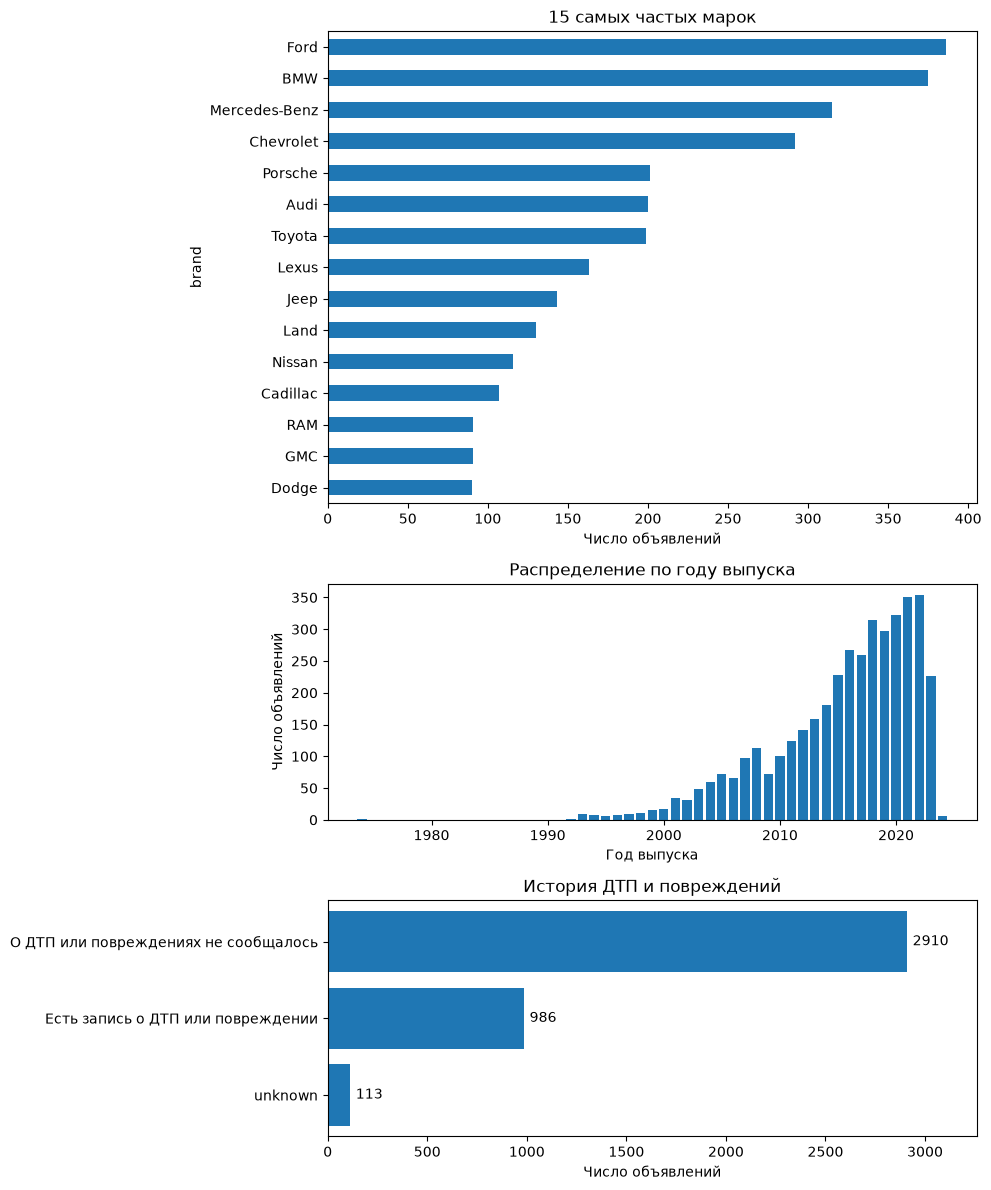

In [5]:
fig, (ax_brand, ax_year, ax_accident) = plt.subplots(
    3, 1, figsize=(10, 12), gridspec_kw={"height_ratios": [2, 1, 1]}
)

brands = df_filled["brand"].value_counts().head(15)
brands.sort_values().plot.barh(ax=ax_brand)
ax_brand.set(title="15 самых частых марок", xlabel="Число объявлений")

years = df_filled["model_year"].value_counts().sort_index()
ax_year.bar(years.index, years.values)
ax_year.set(
    title="Распределение по году выпуска",
    xlabel="Год выпуска",
    ylabel="Число объявлений",
)

accidents = df_filled["accident"].value_counts().rename(index={
    "None reported": "О ДТП или повреждениях не сообщалось",
    "At least 1 accident or damage reported": "Есть запись о ДТП или повреждении",
    "Unknown": "Нет данных",
})
bars = ax_accident.barh(accidents.index, accidents.values)
ax_accident.invert_yaxis()
ax_accident.bar_label(bars, padding=4)
ax_accident.margins(x=0.12)
ax_accident.set(title="История ДТП и повреждений", xlabel="Число объявлений")

plt.tight_layout()
plt.show()

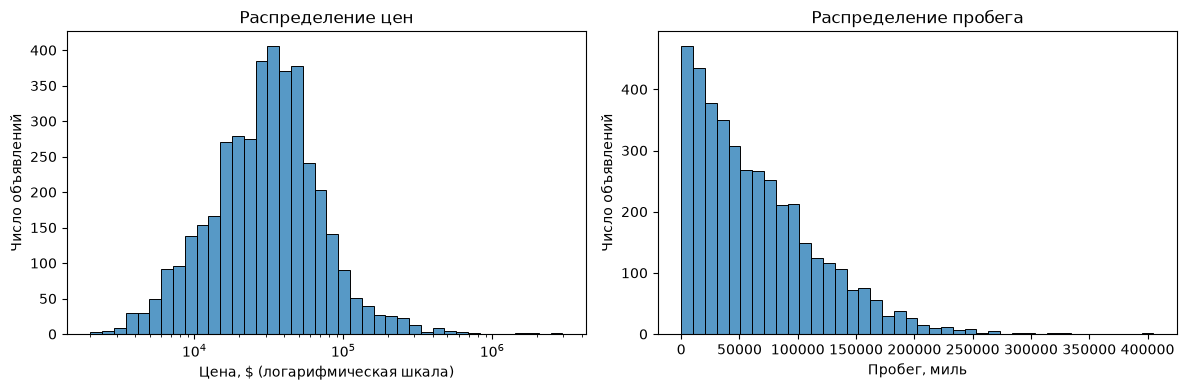

In [6]:
fig, (ax_price, ax_milage) = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=numeric, x="price", bins=40, log_scale=True, ax=ax_price)
ax_price.set(
    title="Распределение цен",
    xlabel="Цена, $ (логарифмическая шкала)",
    ylabel="Число объявлений",
)

sns.histplot(data=numeric, x="milage", bins=40, ax=ax_milage)
ax_milage.set(
    title="Распределение пробега",
    xlabel="Пробег, миль",
    ylabel="Число объявлений",
)

plt.tight_layout()
plt.show()

Из графиков выше мы видим, что большинство автомобилей произведено в `2010-2023` года, пробег в среднем не превышает `150000` миль, а средняя цена авто заключена между `10000` и `100000` долларов.

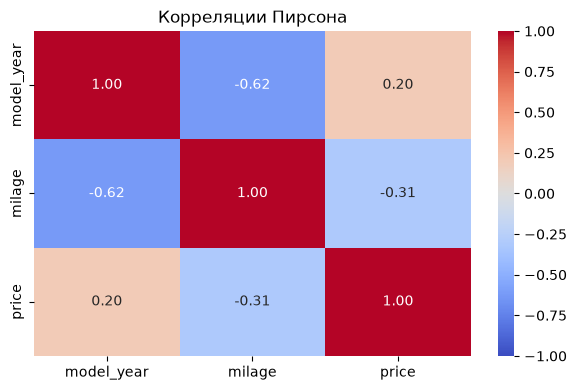

In [7]:
numeric = df_filled[["model_year", "milage", "price"]].copy()

numeric["milage"] = pd.to_numeric(
    numeric["milage"].astype(str).str.replace(r",| mi\.", "", regex=True)
)
numeric["price"] = pd.to_numeric(
    numeric["price"].astype(str).str.replace(r"[$,]", "", regex=True)
)

corr = numeric.corr(method="pearson")

plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляции Пирсона")
plt.tight_layout()
plt.show()

**Из корреляций Пирсона можно заметить естественные закономерности:**
- цена положительно коррелирует зависит от года выпуска авто (чем меньше лет машине, тем она дороже)
- цена отрицательно коррелирует километражу (чем больше миль проехала машина, тем она дешевле)
- километраж отрицательно коррелирует году выпуска (чем меньше лет машине, тем меньше миль она проехала)

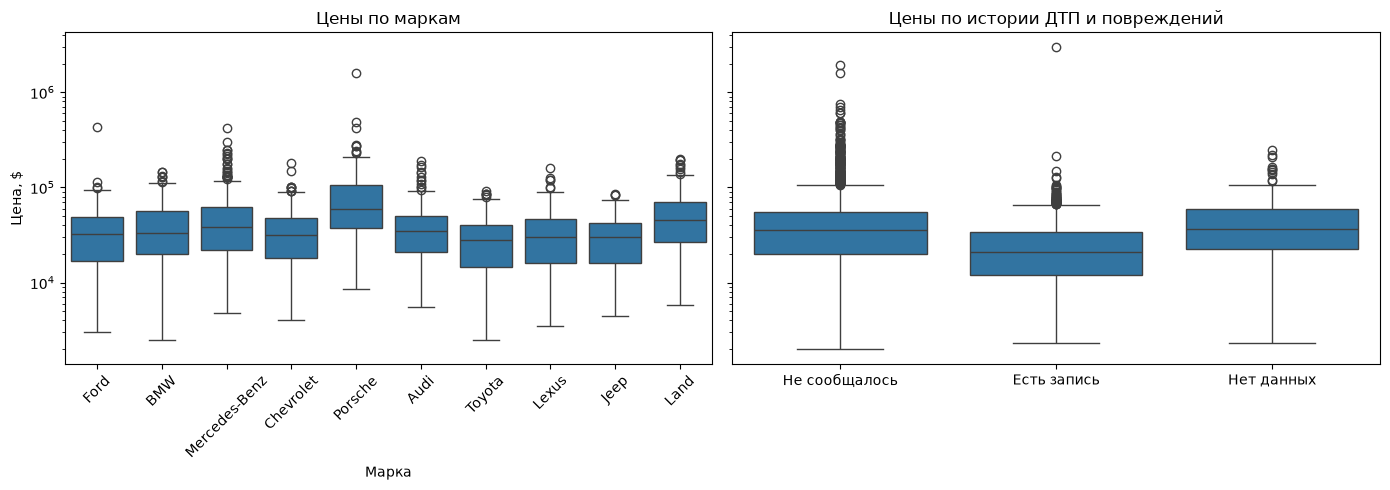

In [8]:
plot_data = df_filled.assign(price=numeric["price"])
top_brands = plot_data["brand"].value_counts().head(10).index

plot_data["accident_label"] = plot_data["accident"].replace({
    "None reported": "Не сообщалось",
    "At least 1 accident or damage reported": "Есть запись",
    "unknown": "Нет данных",
})

fig, (ax_brand, ax_accident) = plt.subplots(
    1, 2, figsize=(14, 5), sharey=True
)

sns.boxplot(data=plot_data, x="brand", y="price", order=top_brands, ax=ax_brand)
ax_brand.set(title="Цены по маркам", xlabel="Марка", ylabel="Цена, $")
ax_brand.tick_params(axis="x", labelrotation=45)

sns.boxplot(
    data=plot_data, x="accident_label", y="price",
    order=["Не сообщалось", "Есть запись", "Нет данных"],
    ax=ax_accident,
)
ax_accident.set(title="Цены по истории ДТП и повреждений", xlabel="", ylabel="")

ax_brand.set_yscale("log")
plt.tight_layout()
plt.show()

На данный момент предварительный EDA ****закончен****, начнем подготовку данных под обучение

Подготовим данные

Проведем **One-Hot Encoding** для `fuel_type`, `engine`, `transmission`, `accident`, `clean_title`

In [9]:
def one_hot(train_cat, test_cat):
    encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
    enc_train = encoder.fit_transform(train_cat)
    enc_test = encoder.transform(test_cat)
    return enc_train, enc_test

def make_split(X, y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    return X_train, X_test, y_train, y_test
    

In [10]:
from sklearn.model_selection import train_test_split

num_cols = ["model_year", "milage"]
cat_cols = ["brand", "fuel_type", "transmission", "accident", "clean_title"]

X = df_filled[num_cols + cat_cols]
y = df_filled["price"]

X_train, X_test, y_train, y_test = make_split(X, y)

print(f"Train: {len(X_train)} объявлений")
print(f"Test:  {len(X_test)} объявлений")

Train: 3207 объявлений
Test:  802 объявлений


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

# Ridge: масштабируем год и пробег, кодируем категории
ridge_preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

ridge_pipe = Pipeline([
    ("preprocess", ridge_preprocess),
    ("model", Ridge()),
])

# Дерево: оставляем год и пробег в исходном масштабе, кодируем категории
tree_preprocess = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

tree_pipe = Pipeline([
    ("preprocess", tree_preprocess),
    ("model", DecisionTreeRegressor(random_state=42)),
])

In [12]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
}

for name, pipe in [("Ridge", ridge_pipe), ("Дерево", tree_pipe)]:
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)

    mae = -scores["test_mae"].mean()
    rmse = -scores["test_rmse"].mean()

    print(f"{name}: MAE = ${mae:,.0f}, RMSE = ${rmse:,.0f}")

Ridge: MAE = $17,032, RMSE = $32,636
Дерево: MAE = $18,458, RMSE = $40,162


In [13]:
from sklearn.model_selection import GridSearchCV

ridge_search = GridSearchCV(
    estimator=ridge_pipe,
    param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100]},
    scoring=scoring,
    cv=cv,
    refit="rmse",
)

ridge_search.fit(X_train, y_train)

results = pd.DataFrame(ridge_search.cv_results_)
results["MAE, $"] = -results["mean_test_mae"]
results["RMSE, $"] = -results["mean_test_rmse"]

display(
    results[["param_model__alpha", "MAE, $", "RMSE, $"]]
    .sort_values("RMSE, $")
    .round(0)
)

best_mae_params = results.loc[results["rank_test_mae"].idxmin(), "params"]
best_rmse_params = ridge_search.best_params_

print("Лучшие параметры по MAE:", best_mae_params)
print("Лучшие параметры по RMSE:", best_rmse_params)

,param_model__alpha,"MAE, $","RMSE, $"
2,1.0,17032.0,32636.0
1,0.0,17037.0,32760.0
0,0.0,17048.0,32810.0
3,10.0,17894.0,35166.0
4,100.0,20784.0,41595.0


Лучшие параметры по MAE: {'model__alpha': 1}
Лучшие параметры по RMSE: {'model__alpha': 1}


In [14]:
tree_search = GridSearchCV(
    estimator=tree_pipe,
    param_grid={"model__max_depth": [2, 4, 6, 8, 12, 16, None]},
    scoring=scoring,
    cv=cv,
    refit="rmse",
)

tree_search.fit(X_train, y_train)

results = pd.DataFrame(tree_search.cv_results_)
results["MAE, $"] = -results["mean_test_mae"]
results["RMSE, $"] = -results["mean_test_rmse"]

display(
    results[["param_model__max_depth", "MAE, $", "RMSE, $"]]
    .sort_values("RMSE, $")
    .round(0)
)

best_mae_params = results.loc[results["rank_test_mae"].idxmin(), "params"]
best_rmse_params = tree_search.best_params_

print("Лучшие параметры по MAE:", best_mae_params)
print("Лучшие параметры по RMSE:", best_rmse_params)

,param_model__max_depth,"MAE, $","RMSE, $"
3,8,16042.0,33392.0
1,4,18081.0,34543.0
2,6,17107.0,35823.0
4,12,16622.0,36529.0
5,16,17220.0,38400.0
6,None,18458.0,40162.0
0,2,21334.0,42568.0


Лучшие параметры по MAE: {'model__max_depth': 8}
Лучшие параметры по RMSE: {'model__max_depth': 8}


**Гипотеза 1 не подтвердилась.** Подбор глубины по RMSE выдал такую же глубину, что и подбор по MAE.

In [15]:
from sklearn.feature_selection import SelectKBest, f_regression

ridge_select_pipe = Pipeline([
    ("preprocess", ridge_preprocess),
    ("select", SelectKBest(score_func=f_regression)),
    ("model", Ridge(alpha=ridge_search.best_params_["model__alpha"])),
])

feature_search = GridSearchCV(
    estimator=ridge_select_pipe,
    param_grid={"select__k": [10, 30, "all"]},
    scoring=scoring,
    cv=cv,
    refit="rmse",
)
feature_search.fit(X_train, y_train)

feature_results = feature_search.cv_results_
display(pd.DataFrame({
    "Число признаков": feature_results["param_select__k"],
    "MAE, $": -feature_results["mean_test_mae"],
    "RMSE, $": -feature_results["mean_test_rmse"],
}).round(0))

best_mae_idx = feature_results["rank_test_mae"].argmin()
best_k_mae = feature_results["params"][best_mae_idx]["select__k"]
best_k_rmse = feature_search.best_params_["select__k"]

print("Лучшее число признаков по MAE:", best_k_mae)
print("Лучшее число признаков по RMSE:", best_k_rmse)

,Число признаков,"MAE, $","RMSE, $"
0,10,19005.0,35399.0
1,30,18131.0,34048.0
2,all,17032.0,32636.0


Лучшее число признаков по MAE: all
Лучшее число признаков по RMSE: all


In [16]:
tree_select_pipe = Pipeline([
    ("preprocess", tree_preprocess),
    ("select", SelectKBest(score_func=f_regression)),
    ("model", DecisionTreeRegressor(max_depth=tree_search.best_params_["model__max_depth"], random_state=42))])

tree_feature_search = GridSearchCV(
    estimator=tree_select_pipe,
    param_grid={"select__k": [10, 30, "all"]},
    scoring=scoring,
    cv=cv,
    refit="rmse",
)
tree_feature_search.fit(X_train, y_train)

tree_feature_results = tree_feature_search.cv_results_

display(pd.DataFrame({
    "Число признаков": tree_feature_results["param_select__k"],
    "MAE, $": -tree_feature_results["mean_test_mae"],
    "RMSE, $": -tree_feature_results["mean_test_rmse"],
}).round(0))

best_mae_idx = tree_feature_results["rank_test_mae"].argmin()
best_k_mae = tree_feature_results["params"][best_mae_idx]["select__k"]
best_k_rmse = tree_feature_search.best_params_["select__k"]

print("Лучшее число признаков по MAE:", best_k_mae)
print("Лучшее число признаков по RMSE:", best_k_rmse)

,Число признаков,"MAE, $","RMSE, $"
0,10,17012.0,35216.0
1,30,16128.0,33102.0
2,all,16042.0,33392.0


Лучшее число признаков по MAE: all
Лучшее число признаков по RMSE: 30


Отбор признаков показал, что для дерева решений лучше выбрать большее число признаков, тогда как для Ridge лучше брать все.

In [17]:
from sklearn.base import clone

cat_cols_no_accident = [col for col in cat_cols if col != "accident"]

ridge_without_accident = clone(ridge_pipe).set_params(
    preprocess__transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_no_accident),
    ]
)

accident_results = []

for name, pipe in [
    ("С accident", ridge_pipe),
    ("Без accident", ridge_without_accident),
]:
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    accident_results.append({
        "Вариант": name,
        "MAE, $": -scores["test_mae"].mean(),
        "RMSE, $": -scores["test_rmse"].mean(),
    })

display(pd.DataFrame(accident_results).round(2))

,Вариант,"MAE, $","RMSE, $"
0,С accident,17032.35,32635.88
1,Без accident,16991.49,32743.91


**Гипотеза № 2 подтвердилась.** На пяти фолдах добавление `accident` снизило среднюю RMSE Ridge примерно на 0,33%, при этом MAE выросла. Вклад признака в прогноз оказался небольшим. Если для упрощения модели допустим незначительный рост RMSE `accident` можно исключить.

In [18]:
from sklearn.compose import TransformedTargetRegressor

ridge_log_price = TransformedTargetRegressor(
    regressor=ridge_pipe,
    func=np.log1p,
    inverse_func=np.expm1,
)

log_price_results = []

for name, model in [
    ("Исходная цена", ridge_pipe),
    ("log1p(price)", ridge_log_price),
]:
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    log_price_results.append({
        "Целевая переменная": name,
        "MAE, $": -scores["test_mae"].mean(),
        "RMSE, $": -scores["test_rmse"].mean(),
    })

display(pd.DataFrame(log_price_results).round(2))

,Целевая переменная,"MAE, $","RMSE, $"
0,Исходная цена,17032.35,32635.88
1,log1p(price),13713.84,30942.21


**Гипотеза № 3 подтвердилась.** После обучения Ridge на `log1p(price)` средняя RMSE снизилась примерно на 5%. RMSE стала ниже на всех пяти фолдах, Средняя MAE также снизилась.

In [19]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error

final_models = {
    "Ridge с log1p(price)": ridge_log_price,
    "Дерево с отбором признаков": tree_feature_search.best_estimator_,
}

test_results = []

for name, model in final_models.items():
    fitted_model = clone(model).fit(X_train, y_train)
    y_pred = fitted_model.predict(X_test)

    test_results.append({
        "Модель": name,
        "MAE на тесте, $": mean_absolute_error(y_test, y_pred),
        "RMSE на тесте, $": mean_squared_error(y_test, y_pred) ** 0.5,
    })

display(pd.DataFrame(test_results).round(2))

,Модель,"MAE на тесте, $","RMSE на тесте, $"
0,Ridge с log1p(price),21004.40,138158.51
1,Дерево с отбором признаков,24611.55,137941.27


**Гипотеза 4 не подтвердилась.** Линейная регрессия даёт больший RMSE, чем дерево решений.

In [20]:
from sklearn.model_selection import cross_val_score
models = {
    "Ridge": ridge_pipe,
    "Дерево": clone(tree_pipe).set_params(
        model__max_depth=tree_search.best_params_["model__max_depth"]
    ),
}

def mean_cv_rmse(model):
    scores = cross_val_score(
        model, X_train, y_train, cv=cv, scoring=scoring["rmse"]
    )
    return -scores.mean()

baseline_rmse = {
    name: mean_cv_rmse(pipe) for name, pipe in models.items()
}

num_cols_no_milage = [col for col in num_cols if col != "milage"]
milage_results = []

for name, pipe in models.items():
    without_milage = clone(pipe).set_params(
        preprocess__transformers=[
            ("num", pipe.get_params()["preprocess__num"], num_cols_no_milage),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ]
    )

    milage_results.append({
        "Модель": name,
        "С пробегом, $": baseline_rmse[name],
        "Без пробега, $": mean_cv_rmse(without_milage),
    })

display(pd.DataFrame(milage_results).round(2))

,Модель,"С пробегом, $","Без пробега, $"
0,Ridge,32635.88,33257.18
1,Дерево,33391.75,38770.45


**Гипотеза 5 подвердилась на обоих моделях.** RMSE снизилась при добавлении пробега, причем для дерева уменьшение ошибки стало существенным.

In [21]:
cat_cols_no_brand = [col for col in cat_cols if col != "brand"]
brand_results = []

for name, pipe in models.items():
    brand_encoder = OneHotEncoder(
        min_frequency=5,
        handle_unknown="infrequent_if_exist",
    )

    with_grouped_brands = clone(pipe).set_params(
        preprocess__transformers=[
            ("num", pipe.get_params()["preprocess__num"], num_cols),
            ("brand", brand_encoder, ["brand"]),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_no_brand),
        ]
    )

    brand_results.append({
        "Модель": name,
        "Обычный one-hot, $": baseline_rmse[name],
        "Редкие марки объединены, $": mean_cv_rmse(with_grouped_brands),
    })

display(pd.DataFrame(brand_results).round(2))

,Модель,"Обычный one-hot, $","Редкие марки объединены, $"
0,Ridge,32635.88,34276.77
1,Дерево,33391.75,34457.30


**Гипотеза 6 не подвердилась.** Для дерева решений RMSE увеличилась, как и для линейной регрессии.